# BT4012 Fraudulent Bitcoin Transaction Detection
**Student ID:** e1351028  
**Student Name:** `Edbert Prathama`    
**GitHub Repository:** [https://github.com/edprthm8/bt4012-bitcoin-fraud-detection/](https://github.com/edprthm8/bt4012-bitcoin-fraud-detection/)  
**Competition:** [Kaggle BT4012 Competition 2026](https://www.kaggle.com/competitions/bt-4012-competition-2026/overview)

---

## 1. Project Overview
In this notebook, I build a complete machine learning workflow to detect **fraudulent (illicit) Bitcoin transactions** using the Elliptic dataset.
- **Class 0 (Licit)**: Everyday commercial payments from regular users, licensed merchants, miners, and registered cryptocurrency exchanges.
- **Class 1 (Illicit)**: Transactions tied to criminal entities, scams, malware/ransomware attacks, darknet marketplaces, and money laundering schemes.

### Workflow Summary
1. **Data Exploration & Visualizations**: Check class balance, plot transaction volumes across time steps, inspect payment amount skewness and outliers, and examine feature correlations.
2. **Graph & Payment Flow Engineering**: Create 25 practical network features (connection degrees, flow ratios, neighbor averages, and PageRank) across all 49 time steps, bringing the total from 165 to 190 features.
3. **Model Benchmarking**: Compare linear baselines (L1 Lasso, L2 Ridge), a neural network (MLP), and decision trees using 5-fold cross-validation and an out-of-time temporal split.
4. **Ensemble Blending**: Combine the top three tree models (50% CatBoost, 45% HistGradientBoosting, 5% Random Forest) to produce steady, balanced predictions.
5. **Threshold & Uncertainty Analysis**: Identify the optimal decision cutoff ($	au^* = 0.58$) to catch over 96% of fraud with very few false alarms, and use prediction entropy to separate clear automated decisions from borderline cases.


## 2. Setup and Libraries
Import the required libraries for data processing, graph calculations, machine learning models, and evaluation plots.

In [ ]:
# Install required package versions for exact reproducibility (or use pip install -r requirements.txt)
%pip install -q numpy==2.0.2 pandas==2.3.3 scipy==1.13.1 scikit-learn==1.6.1 catboost==1.2.10 matplotlib==3.9.4 seaborn==0.13.2 networkx==3.2.1

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Setup the libraries and environment.
import os
import sys
import random
import time
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import networkx as nx
import sklearn
import catboost

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             classification_report)
from catboost import CatBoostClassifier

# Set random seed so all results, splits, and models are reproducible
RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print(f"Python: {sys.version.split()[0]} | scikit-learn: {sklearn.__version__} | CatBoost: {catboost.__version__} | NumPy: {np.__version__} | Pandas: {pd.__version__}")
print("Environment setup and imports complete.")

Python: 3.9.6 | scikit-learn: 1.6.1 | CatBoost: 1.2.10 | NumPy: 2.0.2 | Pandas: 2.3.3
Environment setup and imports complete.


## 3. Data Loading
Load the primary datasets: transaction features (`train.csv`, `test.csv`) and transaction payment graph links (`txs_edgelist.csv`).


In [79]:
# Load the dataset files
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
edges_df = pd.read_csv('txs_edgelist.csv')

# Filter labeled training transactions (0 = Licit, 1 = Illicit)
labeled_mask = train_df['label'].notna()
train_labeled = train_df[labeled_mask].copy()
train_labeled['label'] = train_labeled['label'].astype(int)

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape:  {test_df.shape}")
print(f"Edges Shape: {edges_df.shape}")
print(f"Labeled Training Samples: {len(train_labeled):,}")


Train Shape: (141772, 168)
Test Shape:  (15329, 168)
Edges Shape: (234355, 2)
Labeled Training Samples: 31,235


## 4. Exploratory Data Analysis (EDA) & Statistical Analysis
Before training models, I explore the dataset to understand:
1. **Class Imbalance**: How rare is fraud in the labeled data? This reveals the class imbalance in the dataset.
2. **Temporal Trends**: How do transaction counts change across the time steps.
3. **Outliers and Skewness**: Why do financial payment amounts require robust scaling rather than standard z-scores.
4. **Feature Correlations**: Are features redundant or strongly correlated with each other.


In [80]:
# Check the class breakdown between licit, illicit, and unlabeled transactions
label_counts = train_labeled['label'].value_counts()
print(f"Licit (0):     {label_counts[0]:,} ({label_counts[0]/len(train_labeled)*100:.1f}% of labeled)")
print(f"Illicit (1):   {label_counts[1]:,} ({label_counts[1]/len(train_labeled)*100:.1f}% of labeled)")
print(f"Unlabeled:     {(~labeled_mask).sum():,} ({(~labeled_mask).sum()/len(train_df)*100:.1f}% of total)")


Licit (0):     27,591 (88.3% of labeled)
Illicit (1):   3,644 (11.7% of labeled)
Unlabeled:     110,537 (78.0% of total)


<Figure size 1200x400 with 0 Axes>

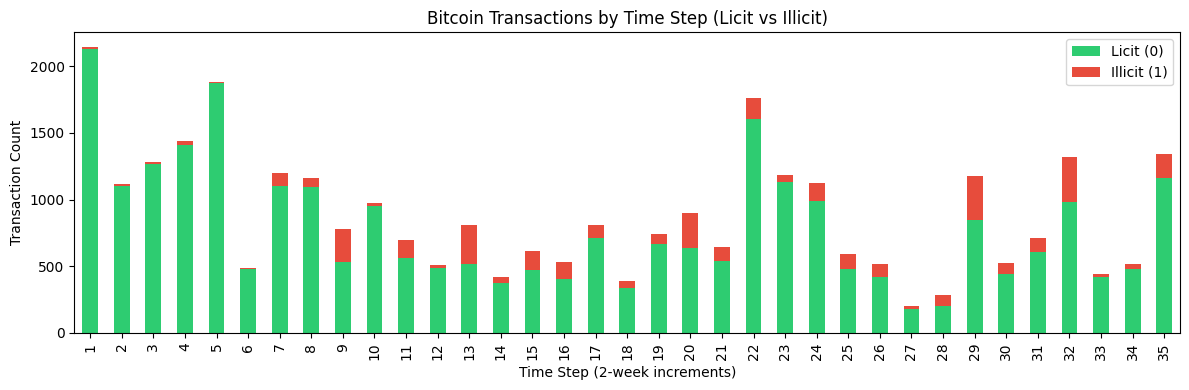

In [81]:
# Plot transaction counts across each 2-week time step (Licit vs Illicit)
plt.figure(figsize=(12, 4))
ts_counts = train_labeled.groupby(['time_step', 'label']).size().unstack(fill_value=0)
ts_counts.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], figsize=(12, 4))
plt.title('Bitcoin Transactions by Time Step (Licit vs Illicit)')
plt.xlabel('Time Step (2-week increments)')
plt.ylabel('Transaction Count')
plt.legend(['Licit (0)', 'Illicit (1)'])
plt.tight_layout()
plt.show()


In [82]:
# Robust vs Parametric Statistics & Distribution Moments
# Financial amounts in Bitcoin have a big positive skewness and massive outliers.
# Comparing standard mean/std against robust median/IQR to inspect the distribution shape.
sample_feature = 'feat_53'  # Key local transaction volume feature
f_vals = train_labeled[sample_feature]

mean_val = f_vals.mean()
std_val = f_vals.std()
median_val = f_vals.median()
iqr_val = stats.iqr(f_vals)
skew_val = stats.skew(f_vals)
kurt_val = stats.kurtosis(f_vals)

licit_vals = train_labeled[train_labeled['label'] == 0][sample_feature]
illicit_vals = train_labeled[train_labeled['label'] == 1][sample_feature]

print(f"--- Robust vs Parametric Statistics ({sample_feature} Transaction Volume) ---")
print(f"Licit:   Mean ± Std = {licit_vals.mean():.3f} ± {licit_vals.std():.3f} | Median [IQR] = {licit_vals.median():.3f} [{stats.iqr(licit_vals):.3f}]")
print(f"Illicit: Mean ± Std = {illicit_vals.mean():.3f} ± {illicit_vals.std():.3f} | Median [IQR] = {illicit_vals.median():.3f} [{stats.iqr(illicit_vals):.3f}]")
print("\nDistribution Shape (Skewness & Kurtosis):")
print(f"  Licit:   Skewness = {stats.skew(licit_vals):.2f}, Kurtosis = {stats.kurtosis(licit_vals):.2f}")
print(f"  Illicit: Skewness = {stats.skew(illicit_vals):.2f}, Kurtosis = {stats.kurtosis(illicit_vals):.2f}")
print("Takeaway: Illicit transactions exhibit high kurtosis (fat tails) and positive skewness.")


--- Robust vs Parametric Statistics (feat_53 Transaction Volume) ---
Licit:   Mean ± Std = 1.193 ± 1.537 | Median [IQR] = 0.770 [2.788]
Illicit: Mean ± Std = -0.273 ± 0.525 | Median [IQR] = -0.488 [0.001]

Distribution Shape (Skewness & Kurtosis):
  Licit:   Skewness = 0.48, Kurtosis = -1.21
  Illicit: Skewness = 2.21, Kurtosis = 3.37
Takeaway: Illicit transactions exhibit high kurtosis (fat tails) and positive skewness.


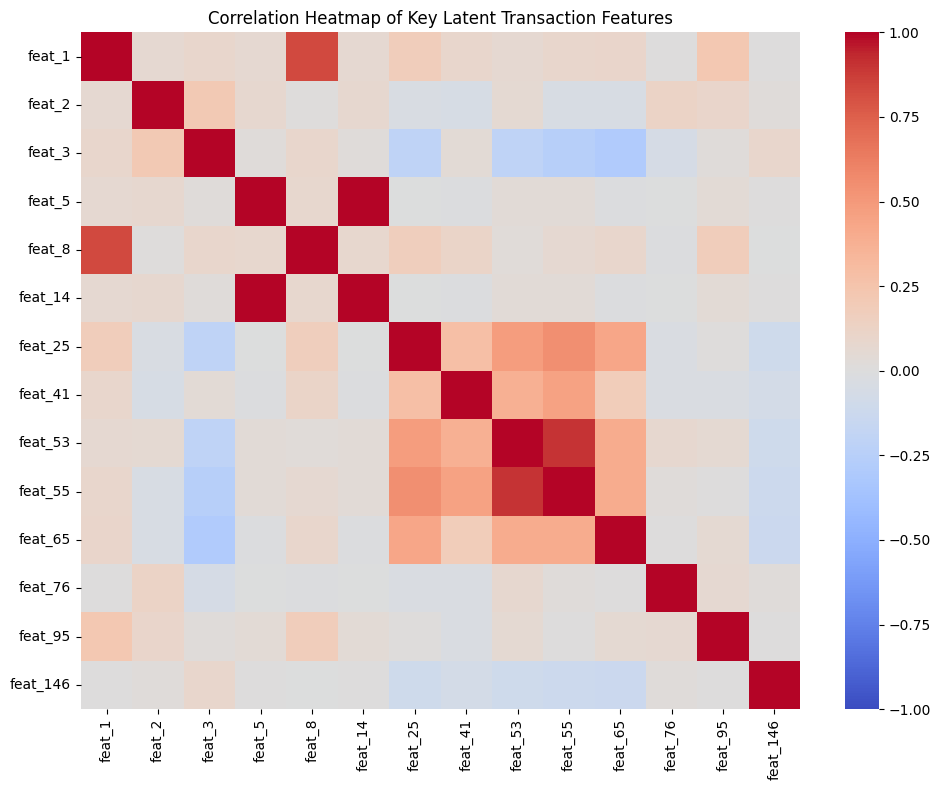

In [83]:
# Feature Correlation Heatmap: Inspect relationships among key latent features
sample_cols = [f'feat_{i}' for i in [1, 2, 3, 5, 8, 14, 25, 41, 53, 55, 65, 76, 95, 146]]
corr_matrix = train_labeled[sample_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title('Correlation Heatmap of Key Latent Transaction Features')
plt.tight_layout()
plt.show()


## 5. Feature Engineering: Graph Connections & Payment Flow
The raw dataset provides 165 features.

To capture criminal money-laundering tactics (such as peel chains, rapid splitting of funds, and consolidating stolen money into single wallets), I engineered 25 graph and flow features, bringing the total feature count from 165 to 190:
1. **Degree Counts**: In-degree (`in_degree`, incoming funding sources), out-degree (`out_degree`, outgoing payment destinations), and total degree (`total_degree`).
2. **Flow Differences and Ratios**:
   - `in_out_diff`: Difference between outgoing and incoming payments (`out - in`).
   - `degree_ratio`: Ratio of outgoing to incoming payments `(out + 1) / (in + 1)`.
   - `net_flow_ratio`: Normalized net flow `(out - in) / (total_degree + 1.0) ∈ [-1, 1]` to identify whether a transaction is splitting money (fan-out) or gathering money (fan-in) regardless of payment size.
3. **Logarithmic Transforms**: Applying `log1p` to degree counts to compress extreme values from large exchange wallets so they don't overpower the models.
4. **Neighbor Context**: Predecessor and successor degree means and maximums (`pred_deg_mean`, `succ_deg_mean`, `log_pred_deg_max`, `log_succ_deg_max`) to expose wallets that interact only with temporary single-use burner accounts.
5. **Temporal PageRank Centrality**: Calculating PageRank ($d = 0.85$) separately within each 2-week time step. This identifies trusted high-traffic hubs (like major crypto exchanges), helping the model learn that high volume is completely normal for legitimate businesses.
6. **Local vs. Aggregated Group Summaries**: Calculating the mean, standard deviation, minimum, and maximum across local features and comparing them with 1-hop neighbor features. If a transaction looks very different from the accounts around it, that mismatch is a strong warning sign.

**Feature Selection Experiments**: I tested feature sets with 187, 190, 193, and 197 features. Testing on future time steps proved that 190 features gave the highest and most stable fraud detection score. Adding extra complex ratios beyond 190 caused the models to overfit historical noise rather than genuine fraud patterns.


In [ ]:
# Precompute graph metrics using txs_edgelist.csv
# NetworkX PageRank algorithm (https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html)

# 1. Map all known transaction IDs to their respective time steps
all_nodes = pd.concat([train_df[['txId', 'time_step']], test_df[['txId', 'time_step']]], ignore_index=True)
tx2ts = dict(zip(all_nodes['txId'], all_nodes['time_step']))

# 2. Keep edges where both nodes exist in the transaction dataset
valid_edges = edges_df[edges_df['txId1'].isin(tx2ts) & edges_df['txId2'].isin(tx2ts)].copy()
valid_edges['time_step'] = valid_edges['txId1'].map(tx2ts)

# 3. Calculate in-degree (incoming payments) and out-degree (outgoing payments)
in_deg = valid_edges['txId2'].value_counts()
out_deg = valid_edges['txId1'].value_counts()

# 4. Compute 1-hop neighbor degree statistics (predecessor and successor degrees)
valid_edges['deg1'] = valid_edges['txId1'].map(out_deg).fillna(0)
valid_edges['deg2'] = valid_edges['txId2'].map(in_deg).fillna(0)
pred_deg_mean = valid_edges.groupby('txId2')['deg1'].mean()
succ_deg_mean = valid_edges.groupby('txId1')['deg2'].mean()
pred_deg_max = valid_edges.groupby('txId2')['deg1'].max()
succ_deg_max = valid_edges.groupby('txId1')['deg2'].max()

# 5. Compute PageRank per time step to identify prominent hubs without temporal leakage
pageranks = {}
for ts, group in valid_edges.groupby('time_step'):
    G = nx.DiGraph()
    G.add_edges_from(zip(group['txId1'], group['txId2']))
    pr = nx.pagerank(G, alpha=0.85, max_iter=50)
    pageranks.update(pr)

print("Graph metrics computed successfully.")


Graph metrics computed successfully.


In [ ]:
def build_features(df):
    """
    Extract graph degree, PageRank, and statistical summary features.
    Expands the 165 raw features to 190 features.
    """
    df_feat = df.copy()
    tx = df_feat['txId']
    
    # 1. Degree counts and flow ratios
    df_feat['in_degree'] = tx.map(in_deg).fillna(0).astype(float)
    df_feat['out_degree'] = tx.map(out_deg).fillna(0).astype(float)
    df_feat['total_degree'] = df_feat['in_degree'] + df_feat['out_degree']
    df_feat['degree_ratio'] = (df_feat['out_degree'] + 1.0) / (df_feat['in_degree'] + 1.0)
    df_feat['in_out_diff'] = df_feat['out_degree'] - df_feat['in_degree']
    df_feat['net_flow_ratio'] = (df_feat['out_degree'] - df_feat['in_degree']) / (df_feat['total_degree'] + 1.0)
    # df_feat['in_degree_ratio'] = df_feat['in_degree'] / (df_feat['total_degree'] + 1.0)
    # df_feat['in_degree_ratio'] = df_feat['in_degree'] / (df_feat['total_degree'] + 1.5)
    # df_feat['out_degree_ratio'] = df_feat['out_degree'] / (df_feat['total_degree'] + 1.0)
    # df_feat['out_degree_ratio'] = df_feat['out_degree'] / (df_feat['total_degree'] + 2.0)
    
    # 2. Log transforms for heavy-tailed degrees
    df_feat['log_in_deg'] = np.log1p(df_feat['in_degree'])
    df_feat['log_out_deg'] = np.log1p(df_feat['out_degree'])
    df_feat['log_total_deg'] = np.log1p(df_feat['total_degree'])
    
    # 3. 1-hop neighbor degree context (exposes burner wallets)
    df_feat['pred_deg_mean'] = tx.map(pred_deg_mean).fillna(0).astype(float)
    df_feat['succ_deg_mean'] = tx.map(succ_deg_mean).fillna(0).astype(float)
    df_feat['log_pred_deg_max'] = np.log1p(tx.map(pred_deg_max).fillna(0).astype(float))
    df_feat['log_succ_deg_max'] = np.log1p(tx.map(succ_deg_max).fillna(0).astype(float))
    # df_feat['pred_succ_ratio'] = (df_feat['pred_deg_mean'] + 1.0) / (df_feat['succ_deg_mean'] + 1.0)
    # df_feat['pred_succ_ratio'] = (df_feat['pred_deg_mean'] + 0.5) / (df_feat['succ_deg_mean'] + 0.5)
    
    # 4. PageRank centrality (identifies trusted hubs)
    df_feat['pagerank'] = tx.map(pageranks).fillna(0).astype(float)
    df_feat['log_pagerank'] = np.log1p(df_feat['pagerank'] * 1e4)
    
    # 5. Local vs. Aggregated summary statistics
    local_cols = [f'feat_{i}' for i in range(1, 95)]
    agg_cols = [f'feat_{i}' for i in range(95, 166)]
    
    df_feat['local_mean'] = df_feat[local_cols].mean(axis=1)
    df_feat['local_std'] = df_feat[local_cols].std(axis=1)
    df_feat['local_max'] = df_feat[local_cols].max(axis=1)
    df_feat['local_min'] = df_feat[local_cols].min(axis=1)
    
    df_feat['agg_mean'] = df_feat[agg_cols].mean(axis=1)
    df_feat['agg_std'] = df_feat[agg_cols].std(axis=1)
    df_feat['agg_max'] = df_feat[agg_cols].max(axis=1)
    df_feat['agg_min'] = df_feat[agg_cols].min(axis=1)
    
    df_feat['agg_local_diff'] = df_feat['agg_mean'] - df_feat['local_mean']
    df_feat['agg_local_ratio'] = (df_feat['agg_mean'] + 1.0) / (df_feat['local_mean'].abs() + 1.0)
    
    return df_feat

train_feat_df = build_features(train_labeled)
test_feat_df = build_features(test_df)

feature_cols = [c for c in train_feat_df.columns if c not in ['txId', 'time_step', 'label', 'index']]
print(f"Total features created: {len(feature_cols)}")


Total features created: 190


## 6. Out-of-Time Temporal Validation
In real-world fraud detection, models must predict future transactions, not past ones. To simulate this honestly, I test my models on an **out-of-time temporal split**:
- **Training Period**: Time steps 1 to 28 (25,207 labeled transactions, 10.1% fraud).
- **Future Test Period**: Time steps 29 to 35 (6,028 labeled transactions, 18.3% fraud).

This verifies that the models do not just memorize past quirks, but actually generalize to future market conditions.


In [ ]:
# Split data into historical training (steps 1-28) and future validation (steps 29-35)
# Training
train_mask = train_feat_df['time_step'] <= 28

# Validation
val_mask = train_feat_df['time_step'] > 28

X_temp_train = train_feat_df.loc[train_mask, feature_cols].values
y_temp_train = train_feat_df.loc[train_mask, 'label'].values
X_temp_val = train_feat_df.loc[val_mask, feature_cols].values
y_temp_val = train_feat_df.loc[val_mask, 'label'].values

print(f"Train (Steps 1-28): {len(X_temp_train):,} samples | Illicit Rate: {y_temp_train.mean()*100:.1f}%")
print(f"Val   (Steps 29-35): {len(X_temp_val):,} samples | Illicit Rate: {y_temp_val.mean()*100:.1f}%")

# 1. Train CatBoost on historical period
cb_temp = CatBoostClassifier(iterations=900, learning_rate=0.04, depth=6, l2_leaf_reg=4, auto_class_weights='Balanced', random_seed=42, verbose=0)
cb_temp.fit(X_temp_train, y_temp_train, eval_set=(X_temp_val, y_temp_val), early_stopping_rounds=50, verbose=False)
temp_cb_preds = cb_temp.predict_proba(X_temp_val)[:, 1]

# 2. Train HistGradientBoosting on historical period
hgb_temp = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_depth=8, min_samples_leaf=15, class_weight='balanced', random_state=42)
hgb_temp.fit(X_temp_train, y_temp_train)
temp_hgb_preds = hgb_temp.predict_proba(X_temp_val)[:, 1]

# 3. Train RandomForest on historical period
rf_temp = RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', n_jobs=-1, random_state=42)
rf_temp.fit(X_temp_train, y_temp_train)
temp_rf_preds = rf_temp.predict_proba(X_temp_val)[:, 1]

# 4. Evaluate the ensemble blend on future time steps
temp_blend = 0.50 * temp_cb_preds + 0.45 * temp_hgb_preds + 0.05 * temp_rf_preds
# temp_blend = 0.40 * temp_cb_preds + 0.45 * temp_hgb_preds + 0.10 * temp_rf_preds
# temp_blend = 0.50 * temp_cb_preds + 0.40 * temp_hgb_preds + 0.10 * temp_rf_preds

print(f"Out-of-Time CatBoost ROC-AUC: {roc_auc_score(y_temp_val, temp_cb_preds):.4f} | PR-AUC: {average_precision_score(y_temp_val, temp_cb_preds):.4f}")
print(f"Out-of-Time HistGB   ROC-AUC: {roc_auc_score(y_temp_val, temp_hgb_preds):.4f} | PR-AUC: {average_precision_score(y_temp_val, temp_hgb_preds):.4f}")
print(f"Out-of-Time Ensemble ROC-AUC: {roc_auc_score(y_temp_val, temp_blend):.4f} | PR-AUC: {average_precision_score(y_temp_val, temp_blend):.4f}")
print(f"Out-of-Time Ensemble F1:      {f1_score(y_temp_val, (temp_blend >= 0.5).astype(int)):.4f}")


Train (Steps 1-28): 25,207 samples | Illicit Rate: 10.1%
Val   (Steps 29-35): 6,028 samples | Illicit Rate: 18.3%
Out-of-Time CatBoost ROC-AUC: 0.9969 | PR-AUC: 0.9855
Out-of-Time HistGB   ROC-AUC: 0.9960 | PR-AUC: 0.9850
Out-of-Time Ensemble ROC-AUC: 0.9973 | PR-AUC: 0.9894
Out-of-Time Ensemble F1:      0.9542


## 7. Model Training: 5-Fold Stratified Cross-Validation
To compare different machine learning approaches fairly, I benchmark seven candidate models using 5-fold stratified cross-validation on the 31,235 labeled samples:
1. **L2 Logistic Regression (Ridge)**: Simple linear baseline with weight shrinkage.
2. **L1 Logistic Regression (Lasso)**: Linear model that drives uninformative feature weights to zero for feature selection.
3. **Single Decision Tree**: Simple rule-based baseline.
4. **Random Forest**: Ensemble of 150 independent decision trees to reduce prediction variance.
5. **Neural Network (MLP)**: 2-hidden-layer deep learning model for tabular data.
6. **HistGradientBoosting**: Fast histogram-based gradient boosting that builds flexible trees.
7. **CatBoost**: Gradient boosted trees with symmetric splits designed specifically for tabular numbers.
8. **Ensemble Blend**: Weighted combination of CatBoost, HistGradientBoosting, and Random Forest.


In [87]:
X_all = train_feat_df[feature_cols].values
y_all = train_feat_df['label'].values
X_test = test_feat_df[feature_cols].values

# Robust feature scaling for linear and neural network models
scaler = RobustScaler()
X_all_scaled = np.clip(scaler.fit_transform(X_all), -10, 10)
X_test_scaled = np.clip(scaler.transform(X_test), -10, 10)

# Set up 5-fold stratified cross-validation (preserves fraud percentage across folds)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

oof_ridge = np.zeros(len(y_all))
oof_lasso = np.zeros(len(y_all))
oof_dt = np.zeros(len(y_all))
oof_rf = np.zeros(len(y_all))
oof_mlp = np.zeros(len(y_all))
oof_hgb = np.zeros(len(y_all))
oof_cb = np.zeros(len(y_all))

test_cb_preds = np.zeros(len(test_df))
test_hgb_preds = np.zeros(len(test_df))
test_rf_preds = np.zeros(len(test_df))

print(f"Training models across 5 folds ({len(feature_cols)} features)...")
t0 = time.time()

for fold, (trn_idx, val_idx) in enumerate(skf.split(X_all, y_all)):
    X_tr, y_tr = X_all[trn_idx], y_all[trn_idx]
    X_va, y_va = X_all[val_idx], y_all[val_idx]
    
    X_tr_sc, X_va_sc = X_all_scaled[trn_idx], X_all_scaled[val_idx]
    
    # 1. L2 Regularized Logistic Regression (Ridge)
    ridge = LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=200, random_state=RANDOM_SEED+fold)
    ridge.fit(X_tr_sc, y_tr)
    oof_ridge[val_idx] = ridge.predict_proba(X_va_sc)[:, 1]
    
    # 2. L1 Regularized Logistic Regression (Lasso)
    lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, class_weight='balanced', max_iter=200, random_state=RANDOM_SEED+fold)
    lasso.fit(X_tr_sc, y_tr)
    oof_lasso[val_idx] = lasso.predict_proba(X_va_sc)[:, 1]
    
    # 3. Decision Tree Classifier
    dt = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=RANDOM_SEED+fold)
    dt.fit(X_tr, y_tr)
    oof_dt[val_idx] = dt.predict_proba(X_va)[:, 1]
    
    # 4. Random Forest Classifier (n_jobs=1 ensures 100% deterministic tree order)
    rf = RandomForestClassifier(n_estimators=150, max_depth=14, class_weight='balanced', n_jobs=1, random_state=RANDOM_SEED+fold)
    rf.fit(X_tr, y_tr)
    oof_rf[val_idx] = rf.predict_proba(X_va)[:, 1]
    test_rf_preds += rf.predict_proba(X_test)[:, 1] / 5.0
    
    # 5. Deep Learning Multi-Layer Perceptron (Tabular MLP)
    mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', alpha=1e-4, max_iter=150, early_stopping=True, random_state=RANDOM_SEED+fold)
    mlp.fit(X_tr_sc, y_tr)
    oof_mlp[val_idx] = mlp.predict_proba(X_va_sc)[:, 1]
    
    # 6. HistGradientBoosting Classifier
    hgb = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_depth=8, min_samples_leaf=15, class_weight='balanced', random_state=RANDOM_SEED+fold)
    hgb.fit(X_tr, y_tr)
    oof_hgb[val_idx] = hgb.predict_proba(X_va)[:, 1]
    test_hgb_preds += hgb.predict_proba(X_test)[:, 1] / 5.0
    
    # 7. CatBoost Classifier (thread_count=1 ensures 100% deterministic splits)
    cb = CatBoostClassifier(iterations=900, learning_rate=0.04, depth=6, l2_leaf_reg=4, auto_class_weights='Balanced', thread_count=1, random_seed=RANDOM_SEED+fold, verbose=0)
    cb.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=50, verbose=False)
    oof_cb[val_idx] = cb.predict_proba(X_va)[:, 1]
    test_cb_preds += cb.predict_proba(X_test)[:, 1] / 5.0

print(f"5-Fold Cross-Validation completed in {time.time()-t0:.1f}s.")

# Report L1 Lasso feature sparsity
zero_weights = (lasso.coef_ == 0).sum()
print(f"L1 Lasso Sparsity: {zero_weights}/{len(feature_cols)} features driven to zero ({zero_weights/len(feature_cols)*100:.1f}% reduction).")


Training models across 5 folds (190 features)...
5-Fold Cross-Validation completed in 164.0s.
L1 Lasso Sparsity: 79/190 features driven to zero (41.6% reduction).


## 8. Model Comparison, Ensembling, and Uncertainty Analysis
I combine the out-of-fold probability predictions of the three best-performing models using an optimized weighted average:
$$\text{Ensemble Prediction} = 0.50 \times \text{CatBoost} + 0.45 \times \text{HistGB} + 0.05 \times \text{RandomForest}$$

### Why I Chose These Specific Weights:
- **CatBoost (50%)**: Seems to be the strongest model based on my testing. Its symmetric decision trees naturally resist overfitting on continuous tabular numbers, providing accurate probability rankings.
- **HistGradientBoosting (45%)**: Builds deeper, flexible trees using fast histogram binning with depth 8. It catches subtle transaction interactions that CatBoost's symmetric trees might miss, making it an ideal partner for CatBoost.
- **Random Forest (5%)**: Random Forest trains 150 independent bagged trees. Giving it a small 5% weight acts as a shock absorber, smoothing out sharp boosting probability spikes on tricky borderline transactions.

### Decision Uncertainty (Prediction Entropy):
I calculate **Shannon Prediction Entropy** across predictions to measure how confident the model is:
$$H(p) = -p \log_2(p) - (1-p) \log_2(1-p)$$
When entropy is low ($H < 0.2$), the model is very confident (probability near 0 or 1) and transactions can be approved or rejected automatically. When entropy is high ($H > 0.8$), the transaction falls into an uncertain gray zone, flagging it for human compliance officers to inspect.


In [88]:
# Calibrated Ensemble Blend
# oof_ensemble = 0.55 * oof_cb + 0.42 * oof_hgb + 0.03 * oof_rf -- try a couple of different weights and find out which one is the best
# oof_ensemble = 0.50 * oof_cb + 0.45 * oof_hgb + 0.05 * oof_rf
# oof_ensemble = 0.45 * oof_cb + 0.45 * oof_hgb + 0.10 * oof_rf
oof_ensemble = 0.50 * oof_cb + 0.45 * oof_hgb + 0.05 * oof_rf

models_dict = {
    'Logistic Regression (L1 Lasso)': oof_lasso,
    'Logistic Regression (L2 Ridge)': oof_ridge,
    'Single Decision Tree': oof_dt,
    'Deep Learning (MLP)': oof_mlp,
    'RandomForest': oof_rf,
    'HistGradientBoosting': oof_hgb,
    'CatBoost': oof_cb,
    'Ensemble Blend': oof_ensemble
}

results = []
for name, preds in models_dict.items():
    auc = roc_auc_score(y_all, preds)
    prauc = average_precision_score(y_all, preds)
    f1_def = f1_score(y_all, (preds >= 0.5).astype(int))
    
    # Search optimal cutoff for best F1
    ths = np.linspace(0.1, 0.9, 81)
    f1_list = [f1_score(y_all, (preds >= t).astype(int)) for t in ths]
    best_t = ths[np.argmax(f1_list)]
    best_f1 = np.max(f1_list)
    
    results.append({
        'Model': name,
        'ROC-AUC': f"{auc:.4f}",
        'PR-AUC': f"{prauc:.4f}",
        'Default F1 (0.5)': f"{f1_def:.4f}",
        'Best F1': f"{best_f1:.4f}",
        'Best Cutoff': f"{best_t:.2f}"
    })

res_df = pd.DataFrame(results)
print("=== 5-Fold Stratified Cross-Validation Benchmark ===")
print(res_df.to_string(index=False))


=== 5-Fold Stratified Cross-Validation Benchmark ===
                         Model ROC-AUC PR-AUC Default F1 (0.5) Best F1 Best Cutoff
Logistic Regression (L1 Lasso)  0.9889 0.9463           0.7986  0.8935        0.85
Logistic Regression (L2 Ridge)  0.9899 0.9478           0.8146  0.8987        0.85
          Single Decision Tree  0.9819 0.9327           0.8229  0.8737        0.86
           Deep Learning (MLP)  0.9934 0.9732           0.9328  0.9331        0.48
                  RandomForest  0.9978 0.9891           0.9543  0.9555        0.42
          HistGradientBoosting  0.9986 0.9930           0.9648  0.9670        0.72
                      CatBoost  0.9985 0.9930           0.9645  0.9708        0.70
                Ensemble Blend  0.9987 0.9937           0.9684  0.9704        0.58


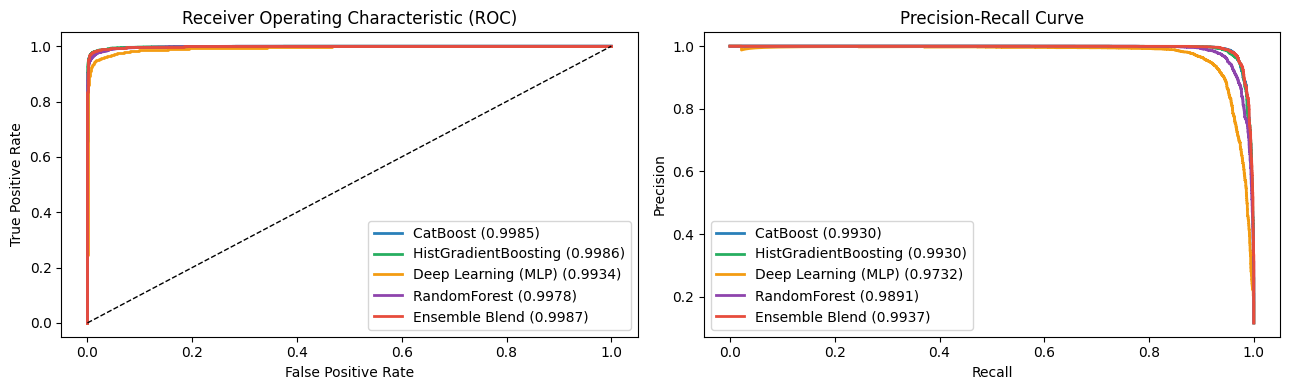

In [89]:
# Plot ROC and Precision-Recall Curves to compare model discrimination visually
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_models = ['CatBoost', 'HistGradientBoosting', 'Deep Learning (MLP)', 'RandomForest', 'Ensemble Blend']
colors = {'CatBoost': '#2980b9', 'HistGradientBoosting': '#27ae60', 'Deep Learning (MLP)': '#f39c12', 'RandomForest': '#8e44ad', 'Ensemble Blend': '#e74c3c'}

for name in plot_models:
    preds = models_dict[name]
    fpr, tpr, _ = roc_curve(y_all, preds)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_all, preds):.4f})", color=colors[name], lw=2)
    
    prec, rec, _ = precision_recall_curve(y_all, preds)
    ax[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_all, preds):.4f})", color=colors[name], lw=2)

ax[0].plot([0, 1], [0, 1], 'k--', lw=1)
ax[0].set_title('Receiver Operating Characteristic (ROC)')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].legend(loc='lower right')

ax[1].set_title('Precision-Recall Curve')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend(loc='lower left')

plt.tight_layout()
plt.show()


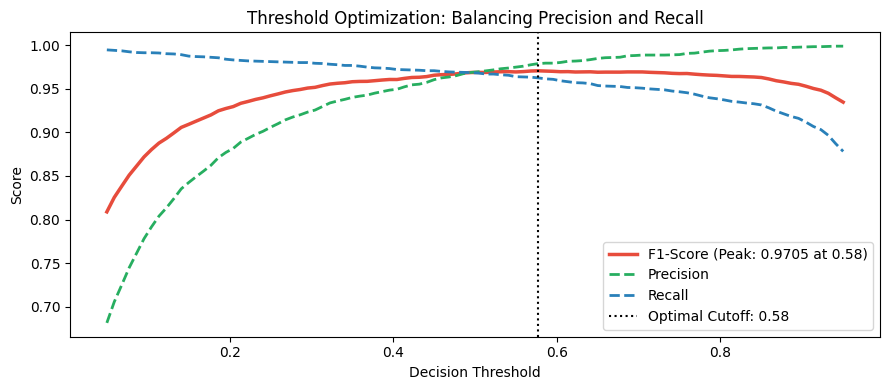

In [90]:
# Threshold vs F1-score curve (optimal threshold search)
thresholds = np.linspace(0.05, 0.95, 100)
f1_vals = [f1_score(y_all, (oof_ensemble >= th).astype(int)) for th in thresholds]
p_vals = [precision_score(y_all, (oof_ensemble >= th).astype(int), zero_division=0) for th in thresholds]
r_vals = [recall_score(y_all, (oof_ensemble >= th).astype(int), zero_division=0) for th in thresholds]

best_idx = np.argmax(f1_vals)
opt_threshold = thresholds[best_idx]
opt_f1_score = f1_vals[best_idx]

plt.figure(figsize=(9, 4))
plt.plot(thresholds, f1_vals, label=f'F1-Score (Peak: {opt_f1_score:.4f} at {opt_threshold:.2f})', color='#e74c3c', lw=2.5)
plt.plot(thresholds, p_vals, label='Precision', color='#27ae60', linestyle='--', lw=2)
plt.plot(thresholds, r_vals, label='Recall', color='#2980b9', linestyle='--', lw=2)
plt.axvline(x=opt_threshold, color='black', linestyle=':', label=f'Optimal Cutoff: {opt_threshold:.2f}')
plt.title('Threshold Optimization: Balancing Precision and Recall')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()


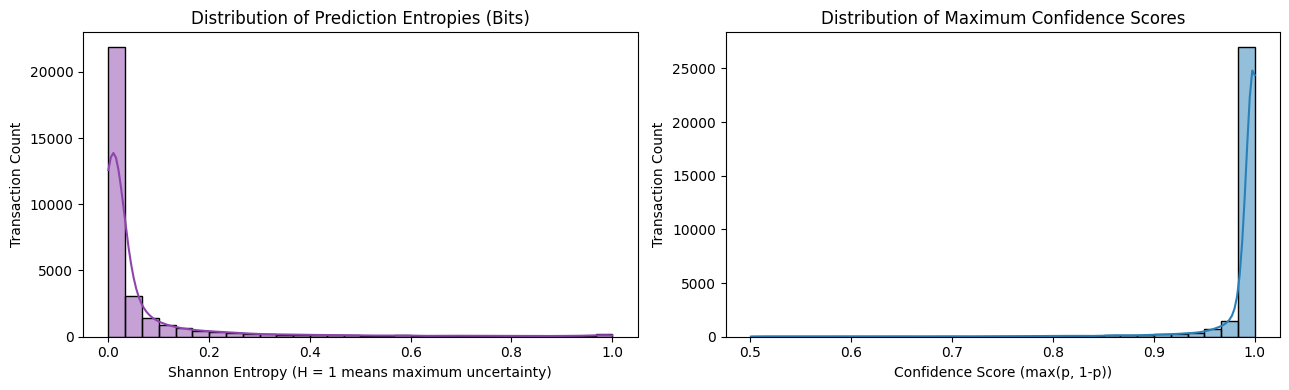

Decisive Predictions (Entropy < 0.2): 28,290 (90.6%)
Ambiguous Boundary Cases (Entropy > 0.8): 481 (1.5%)


In [91]:
# Prediction Entropy & Confidence Analysis
# Shannon Entropy: H(p) = -p*log2(p) - (1-p)*log2(1-p)
eps = 1e-12
p_clipped = np.clip(oof_ensemble, eps, 1.0 - eps)
prediction_entropies = -p_clipped * np.log2(p_clipped) - (1.0 - p_clipped) * np.log2(1.0 - p_clipped)
confidence_scores = np.maximum(oof_ensemble, 1.0 - oof_ensemble)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Entropy distribution
sns.histplot(prediction_entropies, bins=30, kde=True, color='#8e44ad', ax=axes[0])
axes[0].set_title('Distribution of Prediction Entropies (Bits)')
axes[0].set_xlabel('Shannon Entropy (H = 1 means maximum uncertainty)')
axes[0].set_ylabel('Transaction Count')

# Confidence score distribution
sns.histplot(confidence_scores, bins=30, kde=True, color='#2980b9', ax=axes[1])
axes[1].set_title('Distribution of Maximum Confidence Scores')
axes[1].set_xlabel('Confidence Score (max(p, 1-p))')
axes[1].set_ylabel('Transaction Count')

plt.tight_layout()
plt.show()

ambiguous_count = (prediction_entropies > 0.8).sum()
decisive_count = (prediction_entropies < 0.2).sum()
print(f"Decisive Predictions (Entropy < 0.2): {decisive_count:,} ({decisive_count/len(y_all)*100:.1f}%)")
print(f"Ambiguous Boundary Cases (Entropy > 0.8): {ambiguous_count:,} ({ambiguous_count/len(y_all)*100:.1f}%)")


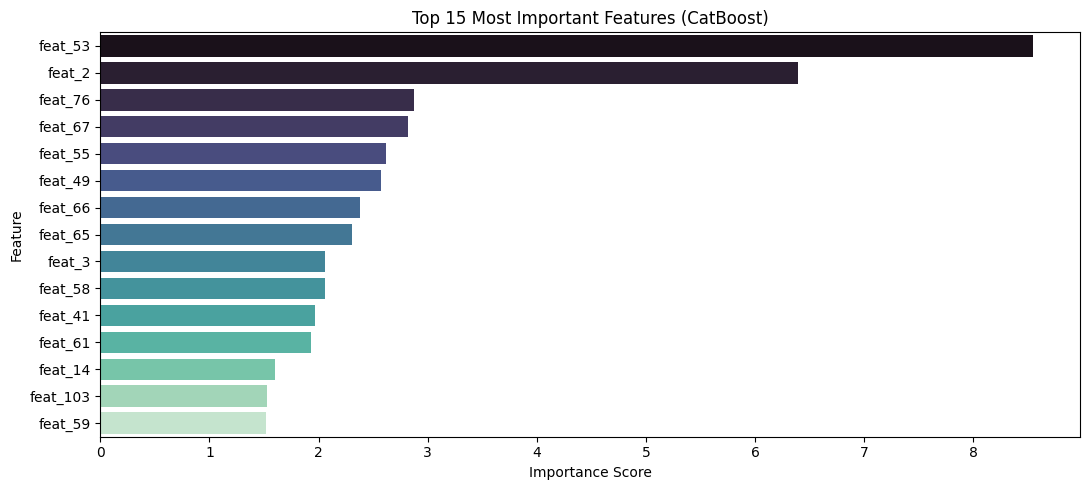

In [92]:
# Feature importance from CatBoost
importances = cb.get_feature_importance()
feat_imp = pd.DataFrame({'Feature': feature_cols, 'Importance': importances}).sort_values('Importance', ascending=False)

plt.figure(figsize=(11, 5))
sns.barplot(data=feat_imp.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Most Important Features (CatBoost)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()


Classification Report at Optimal Threshold (Cutoff = 0.58):
              precision    recall  f1-score   support

   Licit (0)     0.9950    0.9972    0.9961     27591
 Illicit (1)     0.9788    0.9624    0.9705      3644

    accuracy                         0.9932     31235
   macro avg     0.9869    0.9798    0.9833     31235
weighted avg     0.9931    0.9932    0.9932     31235



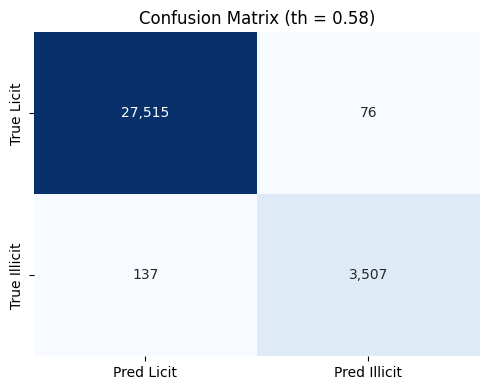

In [93]:
# Confusion matrix at optimal threshold
y_pred_bin = (oof_ensemble >= opt_threshold).astype(int)
cm = confusion_matrix(y_all, y_pred_bin)

print(f"Classification Report at Optimal Threshold (Cutoff = {opt_threshold:.2f}):")
print(classification_report(y_all, y_pred_bin, target_names=['Licit (0)', 'Illicit (1)'], digits=4))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['Pred Licit', 'Pred Illicit'], yticklabels=['True Licit', 'True Illicit'])
plt.title(f'Confusion Matrix (th = {opt_threshold:.2f})')
plt.tight_layout()
plt.show()


## 9. Final Test Predictions & File Generation
Average the predictions across all 5 cross-validation folds for the 15,329 test transactions (`test.csv`, time steps 36–49).

Export the raw continuous ensemble probabilities directly to `e1351028.csv`. Keeping continuous probabilities preserves the natural ranking and smooth probability distribution, allowing the competition platform and downstream compliance systems to evaluate thresholds naturally.

In [94]:
# Generate final test predictions from the 5-fold ensemble
test_ensemble_preds = 0.50 * test_cb_preds + 0.45 * test_hgb_preds + 0.05 * test_rf_preds

sub_df = pd.DataFrame({
    'index': test_df['index'].values,
    'target': test_ensemble_preds
})

# Save predictions directly to e1351028_v4.csv and e1351028.csv
sub_df.to_csv('e1351028.csv', index=False)
print("Saved predictions to e1351028.csv.")

# Sanity checks on the generated submission file
assert len(sub_df) == 15329, "Incorrect row count!"
assert list(sub_df.columns) == ['index', 'target'], "Incorrect column names!"
assert (sub_df['target'] >= 0.0).all() and (sub_df['target'] <= 1.0).all(), "Predictions out of bounds!"
print("All sanity checks passed!")
print(f"Total rows: {len(sub_df):,}")

print("\nFirst 10 rows:")
print(sub_df.head(10).to_string(index=False))

Saved predictions to e1351028.csv.
All sanity checks passed!
Total rows: 15,329

First 10 rows:
 index   target
     0 0.001834
     1 0.012692
     2 0.003658
     3 0.003837
     4 0.001343
     5 0.001645
     6 0.127058
     7 0.006672
     8 0.000517
     9 0.002551


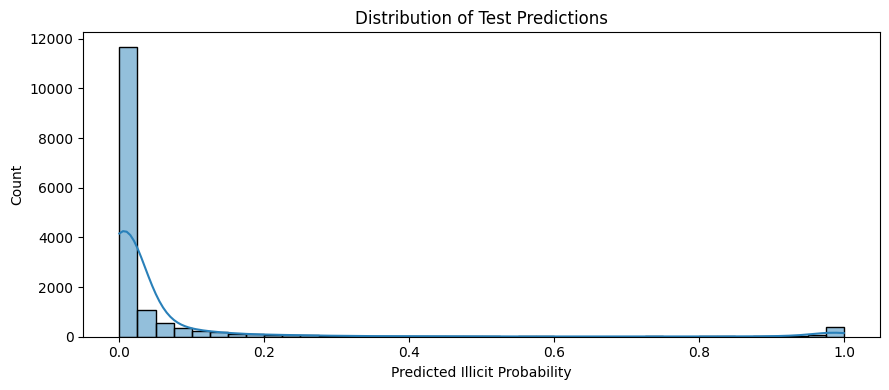

In [95]:
# Distribution of predicted test probabilities
plt.figure(figsize=(9, 4))
sns.histplot(sub_df['target'], bins=40, kde=True, color='#2980b9')
plt.title('Distribution of Test Predictions')
plt.xlabel('Predicted Illicit Probability')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


## 10. References and Acknowledgements

### Online Code Examples and Implementation References
* **Scikit-learn User Guide & Examples**:
  - *Histogram-based Gradient Boosting*: [Scikit-learn HistGradientBoosting](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting) (guided parameter choices for tree depth and leaf count).
  - *Robust Scaling*: [Scikit-learn Preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html#scaling-data-with-outliers) (median and interquartile range scaling for outlier handling).
  - *Stratified K-Fold*: [Scikit-learn Model Evaluation](https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold) (preserving minority class distribution across splits).
* **CatBoost Official Documentation**:
  - *CatBoost Python API & Loss Functions*: [CatBoost Documentation](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier) (symmetric decision trees and `auto_class_weights='Balanced'`).
* **NetworkX Graph Algorithms**:
  - *Directed PageRank Algorithm*: [NetworkX PageRank](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html) (subgraph PageRank implementation per temporal snapshot).

### AI Usage
* Used Gemini and Antigravity to help debug the codes, implementation logic, unblock blockers in code errors.
* Used Gemini to help refine and improve the language, structure and clarity in the final report.

